# Prédire les annulations de réservations hôtelières

**Formation.** Data Analyst, Simplon Lyon

## Contexte
Un groupe hôtelier exploite deux établissements, un City Hotel et un Resort Hotel. Les annulations compliquent la prévision de l'occupation, l'organisation des équipes et le pilotage commercial. La direction veut mieux comprendre ces annulations à partir de son historique de réservations (jeu de données Hotel Booking Demand).

Ce notebook est la partie Machine Learning du projet de groupe. L'exploration, le nettoyage et l'analyse SQL sont faits par Laurie par Ilyes. On part du fichier nettoyé `reservations_nettoyees.csv`.

## Objectifs
- Préparer les données pour la modélisation (colonnes retenues, split, encodage, standardisation)
- Entraîner et comparer des modèles de classification dont une régression logistique
- Régler les paramètres de chaque modèle par validation croisée
- Évaluer les modèles et choisir le meilleur
- Analyser les erreurs et les limites du modèle
- Identifier les variables qui pèsent le plus dans les annulations

## Plan
[3.Split](#3.Split)
4. Nettoyage après le split
5. Modèles
6. Premiers résultats
7. Ajustement des paramètres
8. Importance des variables
9. Choix du modèle
10. Analyse des erreurs
11. Conclusion


## 1. Cadrage et chargement des données

### 1.1 Cadrage

**Question du client**
Dans quelle mesure les informations connues au moment d'une réservation permettent-elles d'anticiper son annulation ? Et quelles variables pèsent le plus ?

**Cible et type de problème**
La cible est `est_annule`. 1 veut dire annulée ou no-show. 0 veut dire que le séjour a eu lieu.

**Moment de la prédiction**
La prédiction se fait au jour de la réservation.

### 1.2 Import des librairies

In [50]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import cross_val_predict, StratifiedKFold

### 1.3 Chargement et contrôle du CSV

In [2]:
# Charge le CSV nettoyé de Laurie et contrôle sa taille, ses colonnes et la part d'annulations
df = pd.read_csv('../data/reservations_nettoyees.csv')
print(df.shape)
print(df.columns.tolist())
print(df['est_annule'].value_counts())
print(df['est_annule'].value_counts(normalize=True))

(86637, 40)
['hotel', 'est_annule', 'delai_reservation_jours', 'annee_arrivee', 'mois_arrivee', 'semaine_arrivee', 'jour_arrivee', 'nuits_weekend', 'nuits_semaine', 'adultes', 'enfants', 'bebes', 'formule_repas', 'pays', 'segment_marche', 'canal_distribution', 'client_fidele', 'annulations_precedentes', 'reservations_precedentes_non_annulees', 'type_chambre_reservee', 'type_chambre_attribuee', 'nb_modifications', 'type_acompte', 'id_agent', 'id_entreprise', 'jours_liste_attente', 'type_client', 'prix_moyen_nuit', 'places_parking', 'nb_demandes_speciales', 'statut_reservation', 'date_statut_reservation', 'duree_sejour', 'total_revenue', 'date_arrivee', 'lead_time_bins', 'tranche_delai', 'num_mois', 'periode', 'type_sejour']
est_annule
0    62652
1    23985
Name: count, dtype: int64
est_annule
0    0.723155
1    0.276845
Name: proportion, dtype: float64


Le fichier contient 86 637 réservations et 40 colonnes. Les 8 dernières de la liste (de `duree_sejour` à `type_sejour`) ont été créées par Laurie pour ses analyses. Elles ne font pas partie des données d'origine. On les retire en 2.1.

La cible `est_annule` vaut 0 pour 62 652 réservations (72,3 %) et 1 pour 23 985 réservations (27,7 %). La classe annulée est la moins fréquente.

<a id="prenettoyage"></a>
## 2. Pré-nettoyage

Dans cette partie on applique seulement des règles fixes. Rien n'est calculé à partir des données (pas de moyenne ni d'écart type). Tout ce qui apprend quelque chose des données est fait après le split sur le train uniquement. Comme ça le jeu de test n'influence pas la préparation.

### 2.1 Retrait des colonnes

On garde les variables retenues et la cible. Toutes les autres colonnes sont retirées. Ce premier tri s'appuie sur le notebook de Laurie et sur la description Kaggle des colonnes. Quand une affirmation vient d'un test sur les données, le test est juste en dessous.

**Les colonnes de Laurie.** Elles ont été créées pour ses analyses et ne font pas partie des données d'origine. On les voit à la fin de la liste des colonnes en 1.3. Ce sont `duree_sejour`, `total_revenue`, `date_arrivee`, `lead_time_bins`, `tranche_delai`, `num_mois`, `periode` et `type_sejour`. Elles sont calculées à partir d'autres colonnes et `total_revenue` utilise le prix.

**Les colonnes qui donnent la réponse.** `statut_reservation` donne la cible. `date_statut_reservation` est, d'après la description Kaggle, la date du dernier statut de la réservation. Elle sert à savoir quand la réservation a été annulée ou quand le client est parti. On ne la connaît donc qu'à la fin.

**Les colonnes qui ne sont pas connues avec certitude à la réservation.** D'après la description Kaggle, `nb_modifications` compte les changements faits entre la saisie de la réservation et l'arrivée ou l'annulation. `jours_liste_attente` est le nombre de jours passés en liste d'attente avant la confirmation au client. `type_chambre_attribuee` peut différer de la chambre réservée à cause de l'hôtel ou d'une demande du client. `places_parking` est une demande du client dont la description ne donne pas le moment. Le test montre qu'aucune réservation avec une place demandée n'est annulée.

**Les colonnes sans intérêt ou en doublon.** `nb_demandes_speciales` est, d'après la description Kaggle, le nombre de demandes spéciales faites par le client. Un nombre seul ne dit pas quelles demandes ont été faites ni si l'hôtel a pu les satisfaire. `canal_distribution` et `segment_marche` décrivent tous les deux la façon dont la réservation est arrivée. Le tableau croisé plus bas montre que presque chaque segment tombe dans un seul canal. On garde le segment car il est plus détaillé. `id_entreprise` est un numéro anonymisé et elle est vide pour la grande majorité des réservations.

**Les dates d'arrivée.** On garde le mois pour la saisonnalité. `annee_arrivee` est retirée car une future réservation aura une année que le modèle n'a jamais vue. Les données vont de juillet 2015 à août 2017. `semaine_arrivee` coupe le mois et le jour du mois n'a pas de sens pour l'hôtel.

**Le prix.** `prix_moyen_nuit` est calculée à partir de toutes les transactions d'hébergement divisées par le nombre de nuits (description Kaggle). On ne peut pas dire que ce prix est fixé au moment de la réservation. On la retire.

In [3]:
# Regarde le taux d'annulation selon le nombre de places de parking demandées
df.groupby('places_parking')['est_annule'].agg(taux='mean', nb='count')

,taux,nb
places_parking,,
0,0.30228,79347
1,0.00000,7257
2,0.00000,28
3,0.00000,3
8,0.00000,2


In [4]:
# Croise le segment de marché avec le canal de distribution
pd.crosstab(df['segment_marche'], df['canal_distribution'])

canal_distribution,Corporate,Direct,GDS,TA/TO,Undefined
segment_marche,,,,,
Aviation,212,0,0,10,0
Complementary,77,530,0,75,0
Corporate,3850,152,0,153,0
Direct,80,11341,1,228,2
Groups,654,638,0,3599,0
Offline TA/TO,94,16,44,13594,0
Online TA,34,126,133,50991,1
Undefined,0,0,0,0,2


In [5]:
# Garde les variables retenues et la cible, retire toutes les autres colonnes
colonnes_gardees = ['hotel', 'mois_arrivee', 'formule_repas', 'pays', 'segment_marche',
                    'type_chambre_reservee', 'type_acompte', 'id_agent', 'type_client',
                    'delai_reservation_jours', 'nuits_weekend', 'nuits_semaine',
                    'adultes', 'enfants', 'bebes', 'client_fidele',
                    'annulations_precedentes', 'reservations_precedentes_non_annulees']

df_ml = df[colonnes_gardees + ['est_annule']].copy()
print(df_ml.shape)
print(df.columns.difference(df_ml.columns).tolist())

(86637, 19)
['annee_arrivee', 'canal_distribution', 'date_arrivee', 'date_statut_reservation', 'duree_sejour', 'id_entreprise', 'jour_arrivee', 'jours_liste_attente', 'lead_time_bins', 'nb_demandes_speciales', 'nb_modifications', 'num_mois', 'periode', 'places_parking', 'prix_moyen_nuit', 'semaine_arrivee', 'statut_reservation', 'total_revenue', 'tranche_delai', 'type_chambre_attribuee', 'type_sejour']


### 2.2 Valeurs manquantes

Ici on regarde les valeurs manquantes des colonnes gardées. Avant le split on traite seulement ce qui se règle avec une règle fixe. Tout ce qui demande de calculer une valeur à partir des données est fait en 4.1, après le split.

In [6]:
# Compte les valeurs manquantes des colonnes gardées
manquants = df_ml.isna().sum()
manquants[manquants > 0]

pays          442
id_agent    11958
enfants         4
dtype: int64

In [7]:
# Compte la valeur "Undefined" dans chaque colonne texte gardée
for col in df_ml.select_dtypes(exclude='number').columns:
    print(col, (df_ml[col] == 'Undefined').sum())

hotel 0
mois_arrivee 0
formule_repas 485
pays 0
segment_marche 2
type_chambre_reservee 0
type_acompte 0
type_client 0


In [8]:
# Regroupe Undefined avec SC dans formule_repas (même catégorie d'après la description Kaggle)
df_ml['formule_repas'] = df_ml['formule_repas'].replace('Undefined', 'SC')
df_ml['formule_repas'].value_counts()

formule_repas
BB    67417
SC     9831
HB     9030
FB      359
Name: count, dtype: int64

In [9]:
# Remplace les pays manquants par la catégorie "Inconnu"
df_ml['pays'] = df_ml['pays'].fillna('Inconnu')

In [10]:
# Transforme id_agent en catégorie (texte) et met "Non renseigné" pour les manquants
df_ml['id_agent'] = df_ml['id_agent'].apply(lambda x: 'Non renseigné' if pd.isna(x) else str(int(x)))

In [11]:
# Vérifie ce qui reste comme valeurs manquantes
manquants = df_ml.isna().sum()
manquants[manquants > 0]

enfants    4
dtype: int64

**Pays.** 442 réservations n'ont pas de pays. On les met dans une catégorie "Inconnu". C'est une règle fixe et on garde les lignes.

**Agent.** D'après la description Kaggle, `id_agent` est l'identifiant de l'agence qui a fait la réservation. C'est un numéro et pas une quantité. On le transforme donc en catégorie. 11 958 réservations n'ont pas d'agent renseigné. On les met dans une catégorie "Non renseigné". On ne parle pas de "sans agent" car un manquant ne veut pas forcément dire absence d'agent.

**Enfants.** 4 valeurs manquantes. Les remplacer par une médiane demande de la calculer sur les données. On le fait en 4.1, après le split.

**Segment de marché.** 2 réservations ont le segment `Undefined`. C'est très peu. On les garde telles quelles.

### 2.3 Variable pays

La colonne `pays` a beaucoup de valeurs différentes. On regarde combien il y en a et comment les réservations se répartissent. On pourra ensuite choisir comment les regrouper.

In [12]:
# Compte les pays différents et regarde les 15 plus fréquents
print(df_ml['pays'].nunique())
vc = df_ml['pays'].value_counts()
pd.DataFrame({'nb': vc, 'part': (vc / len(df_ml)).round(3)}).head(15)

178


,nb,part
pays,,
PRT,26863,0.310
GBR,10400,0.120
FRA,8813,0.102
ESP,7228,0.083
DEU,5385,0.062
ITA,3056,0.035
IRL,3014,0.035
BEL,2078,0.024
BRA,1988,0.023


In [13]:
# Taux d'annulation et nombre de réservations des 10 pays les plus fréquents
top = df_ml['pays'].value_counts().head(10).index
df_ml[df_ml['pays'].isin(top)].groupby('pays')['est_annule'].agg(taux='mean', nb='count').sort_values('nb', ascending=False)

,taux,nb
pays,,
PRT,0.363660,26863
GBR,0.190673,10400
FRA,0.196414,8813
ESP,0.257471,7228
DEU,0.195543,5385
ITA,0.351440,3056
IRL,0.221632,3014
BEL,0.197305,2078
BRA,0.365191,1988


La colonne `pays` a 178 valeurs différentes (la catégorie "Inconnu" comprise). Le Portugal domine avec 26 863 réservations, soit 31,0 % du total. Viennent ensuite le Royaume-Uni (12,0 %), la France (10,2 %) et l'Espagne (8,3 %). Dès le 14e pays, la part est d'environ 1 %.

Le taux d'annulation change d'un pays à l'autre. Il est de 36,4 % pour le Portugal, 36,5 % pour le Brésil et 35,1 % pour l'Italie. Il tombe à 18,3 % pour les Pays-Bas et 19,1 % pour le Royaume-Uni. Le taux global est de 27,7 % (voir 1.3).

Un one-hot complet ferait 178 colonnes. On garde donc les pays les plus fréquents et on regroupe tous les autres dans "Autres". Les pays très présents comme le Portugal restent visibles. Le regroupement se fait en 4.2. La liste des pays rares se calcule sur le train, donc le seuil sera fixé à ce moment-là.

### 2.4 encodage binaire

Une colonne qui n'a que deux valeurs se transforme en 0 et 1 avec une règle fixe. Rien n'est calculé à partir des données, donc on peut le faire avant le split. C'est le cas de `hotel`. Les autres colonnes texte ont plus de deux valeurs et sont encodées en 4.2.

In [14]:
# Transforme hotel en 0/1 avec une règle fixe (Resort Hotel = 0 et City Hotel = 1)
df_ml['hotel'] = df_ml['hotel'].map({'Resort Hotel': 0, 'City Hotel': 1})
df_ml['hotel'].value_counts()

hotel
1    53042
0    33595
Name: count, dtype: int64

`hotel` est maintenant en 0 et 1. Le City Hotel vaut 1 (53 042 réservations) et le Resort Hotel vaut 0 (33 595 réservations). Ça fait bien les 86 637 réservations de 1.3, donc aucune valeur n'a été perdue.

### 2.5 Bilan avant le split

On vérifie l'état de `df_ml` avant de le couper en train et test. On regarde sa taille, le type des colonnes et ce qui reste de valeurs manquantes.

In [15]:
# Résume df_ml : taille, types des colonnes et valeurs non manquantes
df_ml.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 86637 entries, 0 to 86636
Data columns (total 19 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   hotel                                  86637 non-null  int64  
 1   mois_arrivee                           86637 non-null  object 
 2   formule_repas                          86637 non-null  object 
 3   pays                                   86637 non-null  object 
 4   segment_marche                         86637 non-null  object 
 5   type_chambre_reservee                  86637 non-null  object 
 6   type_acompte                           86637 non-null  object 
 7   id_agent                               86637 non-null  object 
 8   type_client                            86637 non-null  object 
 9   delai_reservation_jours                86637 non-null  int64  
 10  nuits_weekend                          86637 non-null  int64  
 11  nu

In [16]:
# Liste les colonnes texte qui restent à encoder en 4.2
df_ml.select_dtypes(exclude='number').columns.tolist()

['mois_arrivee',
 'formule_repas',
 'pays',
 'segment_marche',
 'type_chambre_reservee',
 'type_acompte',
 'id_agent',
 'type_client']

**Bilan**

`df_ml` a 86 637 lignes et 19 colonnes, la cible `est_annule` comprise. Il ne manque plus aucune valeur sauf pour `enfants` qui en a 4. Elles sont remplacées en 4.1, après le split.

Les colonnes texte qui restent sont `mois_arrivee`, `formule_repas`, `pays`, `segment_marche`, `type_chambre_reservee`, `type_acompte`, `id_agent` et `type_client`. Elles sont encodées en 4.2. Toutes les autres colonnes sont numériques.

Le prétraitement avant le split est terminé.

## 3.Split

On sépare les données en deux parties. Le train sert à apprendre et le test sert à évaluer à la fin. Le test n'est utilisé qu'une seule fois, pour juger le modèle final.

### 3.1 Variables explicatives et cible

In [17]:
# Sépare les variables explicatives (X) de la cible (y)
X = df_ml.drop(columns='est_annule')
y = df_ml['est_annule']
print(X.shape, y.shape)

(86637, 18) (86637,)


### 3.2 Split 80/20

On garde 80 % des réservations pour le train et 20 % pour le test. Le split est stratifié sur `est_annule` donc le train et le test gardent ainsi la même part d'annulations que l'ensemble des données. On fixe `random_state` pour retrouver le même découpage à chaque lancement.

In [18]:
# Sépare les données en train (80 %) et test (20 %) en gardant la même part d'annulations
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(69309, 18) (17328, 18)


### 3.3 Vérification

On vérifie les tailles du train et du test et la part d'annulations dans chacun.

In [19]:
# Compare la part d'annulations dans l'ensemble, le train et le test
print(y.value_counts(normalize=True))
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

est_annule
0    0.723155
1    0.276845
Name: proportion, dtype: float64
est_annule
0    0.723153
1    0.276847
Name: proportion, dtype: float64
est_annule
0    0.723165
1    0.276835
Name: proportion, dtype: float64


Le train compte 69 309 réservations et le test 17 328, avec 18 variables chacun. La part d'annulations est de 27,7 % dans l'ensemble des données, dans le train et dans le test. Les trois proportions sont identiques jusqu'à la quatrième décimale. Le split stratifié a bien gardé la même part d'annulations des deux côtés.

<a id="postsplit"></a>
## 4. Nettoyage après le split

Ici on applique ce qui apprend quelque chose des données (une médiane, la liste des catégories, une moyenne). Chaque outil apprend sur le train uniquement, puis on l'applique au train et au test. Le test ne joue donc aucun rôle dans la préparation.

### 4.1 Imputation

Seule la colonne `enfants` a encore des valeurs manquantes. On les remplace par la médiane calculée sur le train.

In [20]:
# Remplace les enfants manquants par la médiane du train, apprise sur le train puis appliquée au test
imputeur = SimpleImputer(strategy='median')
X_train['enfants'] = imputeur.fit_transform(X_train[['enfants']])
X_test['enfants'] = imputeur.transform(X_test[['enfants']])
print(imputeur.statistics_)
print(X_train['enfants'].isna().sum(), X_test['enfants'].isna().sum())

[0.]
0 0


La médiane des enfants apprise sur le train est 0. Les valeurs manquantes de `enfants` sont donc remplacées par 0. Ça veut dire qu'au moins la moitié des réservations du train n'ont pas d'enfant. Il ne reste plus aucune valeur manquante dans le train ni dans le test.

### 4.2 Encodage des variables catégorielles

Les colonnes texte qui restent sont `mois_arrivee`, `formule_repas`, `pays`, `segment_marche`, `type_chambre_reservee`, `type_acompte`, `id_agent` et `type_client`. On les encode en one-hot, avec une colonne 0/1 par catégorie. L'encodeur apprend la liste des catégories sur le train, puis on l'applique au train et au test. Pour `pays` et `id_agent`, qui ont beaucoup de catégories, les plus rares sont regroupées dans "Autres".

**Colonnes sans regroupement.** On encode d'abord `mois_arrivee`, `formule_repas`, `segment_marche`, `type_chambre_reservee`, `type_acompte` et `type_client`. L'encodeur apprend la liste des catégories sur le train (`fit_transform`) puis on l'applique au test (`transform`).

In [21]:
# Encode en one-hot les 6 colonnes sans regroupement : la grille est apprise sur le train puis appliquée au test
colonnes_simples = ['mois_arrivee', 'formule_repas', 'segment_marche', 'type_chambre_reservee', 'type_acompte', 'type_client']

encodeur_simple = OneHotEncoder(handle_unknown='ignore', sparse_output=False)   # l'outil one-hot (ignore = Si test connait pas une colonne, sparse= tab)
noms = encodeur_simple.fit(X_train[colonnes_simples]).get_feature_names_out(colonnes_simples)   # apprend la grille sur le train et note les noms de colonnes

train_simple = pd.DataFrame(encodeur_simple.transform(X_train[colonnes_simples]), columns=noms, index=X_train.index)   # remplit la grille pour le train
test_simple = pd.DataFrame(encodeur_simple.transform(X_test[colonnes_simples]), columns=noms, index=X_test.index)      # remplit la même grille pour le test
print(train_simple.shape, test_simple.shape)

(69309, 40) (17328, 40)


In [22]:
# Affiche le nombre de catégories apprises pour chaque colonne
for nom, cat in zip(colonnes_simples, encodeur_simple.categories_):
    print(nom, len(cat))

mois_arrivee 12
formule_repas 4
segment_marche 8
type_chambre_reservee 9
type_acompte 3
type_client 4


Les 6 colonnes ont respectivement 12, 4, 8, 9, 3 et 4 catégories. Chaque catégorie devient une colonne 0/1, ce qui fait 40 colonnes. Le train et le test ont le même nombre de colonnes et gardent leur nombre de lignes (69 309 et 17 328).

Ces colonnes sont dans des tables provisoires : `train_simple` et `test_simple`. Les colonnes texte d'origine restent dans `X_train` et `X_test`. On les retire à l'assemblage, à la fin de 4.2.

**Pays.** 

`pays` a beaucoup de catégories. On garde chaque pays assez fréquent dans sa propre colonne et on regroupe les pays rares dans "Autres". La fréquence se mesure sur le train.

In [23]:
# Compte les pays gardés et la part des réservations qu'ils couvrent, selon le seuil choisi
vc = X_train['pays'].value_counts()                  # nombre de réservations de chaque pays dans le train
for seuil in [50, 100, 200, 500]:                    # essaie quatre seuils, un après l'autre
    gardes = vc[vc >= seuil]                         # pays qui ont au moins "seuil" réservations
    print(seuil, len(gardes), round(gardes.sum() / len(X_train), 3))

50 44 0.98
100 34 0.97
200 27 0.955
500 17 0.907


In [24]:
seuil_pays = 200

In [25]:
# One-hot de pays : les pays qui ont moins de seuil_pays réservations dans le train vont dans "Autres"
encodeur_pays = OneHotEncoder(min_frequency=seuil_pays, handle_unknown='infrequent_if_exist', sparse_output=False)
encodeur_pays.fit(X_train[['pays']])

# Récupère les noms des nouvelles colonnes
noms_pays = encodeur_pays.get_feature_names_out(['pays'])

train_pays = pd.DataFrame(encodeur_pays.transform(X_train[['pays']]), columns=noms_pays, index=X_train.index)
test_pays = pd.DataFrame(encodeur_pays.transform(X_test[['pays']]), columns=noms_pays, index=X_test.index)

print(train_pays.shape, test_pays.shape)
print(noms_pays[-3:])

(69309, 28) (17328, 28)
['pays_SWE' 'pays_USA' 'pays_infrequent_sklearn']


Avec un seuil de 200 réservations, `pays` donne 28 colonnes. Ce sont 27 pays gardés chacun dans leur colonne et une colonne `pays_infrequent_sklearn` qui regroupe tous les pays rares sous le nom "Autres". Le train et le test ont le même nombre de colonnes (28). Les nombres de lignes restent 69 309 et 17 328.

**Agent.** `id_agent` est un numéro d'agence. On le traite comme une catégorie. Comme pour `pays`, un agent qui a moins de réservations que le seuil dans le train est regroupé dans "Autres". La catégorie "Non renseigné" suit la même règle que les autres.

In [26]:
# Compte les agents gardés et la part des réservations qu'ils couvrent, selon le seuil choisi
vc = X_train['id_agent'].value_counts()              # nombre de réservations de chaque agent dans le train
print('agents au total :', len(vc))
for seuil in [50, 100, 150, 200, 500]:                    # essaie quatre seuils, un après l'autre
    gardes = vc[vc >= seuil]                         # agents qui ont au moins "seuil" réservations
    print(seuil, len(gardes), round(gardes.sum() / len(X_train), 3))

agents au total : 319
50 77 0.964
100 52 0.94
150 35 0.908
200 27 0.889
500 14 0.834


In [27]:
seuil_agent = 150

In [28]:
# One-hot de id_agent : les agents qui ont moins de seuil_agent réservations dans le train vont dans "Autres"
encodeur_agent = OneHotEncoder(min_frequency=seuil_agent, handle_unknown='infrequent_if_exist', sparse_output=False)

encodeur_agent.fit(X_train[['id_agent']])

# Récupère les noms des nouvelles colonnes
noms_agent = encodeur_agent.get_feature_names_out(['id_agent'])

train_agent = pd.DataFrame(encodeur_agent.transform(X_train[['id_agent']]), columns=noms_agent, index=X_train.index)
test_agent = pd.DataFrame(encodeur_agent.transform(X_test[['id_agent']]), columns=noms_agent, index=X_test.index)

print(train_agent.shape, test_agent.shape)
print(noms_agent[-3:])

(69309, 36) (17328, 36)
['id_agent_96' 'id_agent_Non renseigné' 'id_agent_infrequent_sklearn']


Pour `id_agent`, un agent qui a moins de 150 réservations dans le train est regroupé dans "Autres". Le seuil est la variable `seuil_agent`. Avec 150, 35 agents gardent leur propre colonne et couvrent 90,8 % des réservations du train. Avec la colonne "Autres" (`id_agent_infrequent_sklearn`), ça fait 36 colonnes. La catégorie "Non renseigné" garde sa propre colonne. Le train et le test ont le même nombre de colonnes (36).

**Assemblage.** On crée deux nouvelles tables, `X_train_final` et `X_test_final`. Chacun regroupe les colonnes 0/1 des trois encodages (colonnes simples, `pays` et `id_agent`) et les 10 colonnes de `X_train` et `X_test` qui n'avaient pas besoin d'être encodées. Les 8 colonnes texte ne sont pas reprises. `X_train` et `X_test` ne changent pas. Les colonnes sont recollées ligne par ligne grâce au numéro de ligne d'origine, conservé dans chaque table.

In [30]:
# Liste les 8 colonnes texte qui viennent d'être encodées
colonnes_texte = ['mois_arrivee', 'formule_repas', 'pays', 'segment_marche', 'type_chambre_reservee', 'type_acompte', 'id_agent', 'type_client']

# Retire ces colonnes texte et recolle côte à côte les trois tableaux de colonnes 0/1 (axis=1 = en largeur)
X_train_enco = pd.concat([X_train.drop(columns=colonnes_texte), train_simple, train_pays, train_agent], axis=1)
X_test_enco = pd.concat([X_test.drop(columns=colonnes_texte), test_simple, test_pays, test_agent], axis=1)

print(X_train_enco.shape, X_test_enco.shape)

(69309, 114) (17328, 114)


In [31]:
# Vérifie que le train et le test ont les mêmes colonnes, qu'il n'y a plus de texte ni de valeur manquante
print(list(X_train_enco.columns) == list(X_test_enco.columns))
print(X_train_enco.select_dtypes(exclude='number').columns.tolist())
print(X_train_enco.isna().sum().sum(), X_test_enco.isna().sum().sum())

True
[]
0 0


`X_train_enco` a 69 309 lignes et 114 colonnes. `X_test_enco` a 17 328 lignes et 114 colonnes. Ces 114 colonnes sont les 10 colonnes qui n'avaient pas besoin d'être encodées plus les 40, 28 et 36 colonnes des trois encodages. Le train et le test ont exactement les mêmes colonnes, dans le même ordre. Il ne reste aucune colonne texte et aucune valeur manquante.

### 4.3 Log & Standardisation

Seules les 8 colonnes numériques d'origine sont concernées. Les colonnes 0/1 (`hotel`, `client_fidele` et toutes celles issues du one-hot) sont déjà entre 0 et 1. On regarde d'abord la forme de ces 8 colonnes sur le train pour voir si une mise à l'échelle est nécessaire.

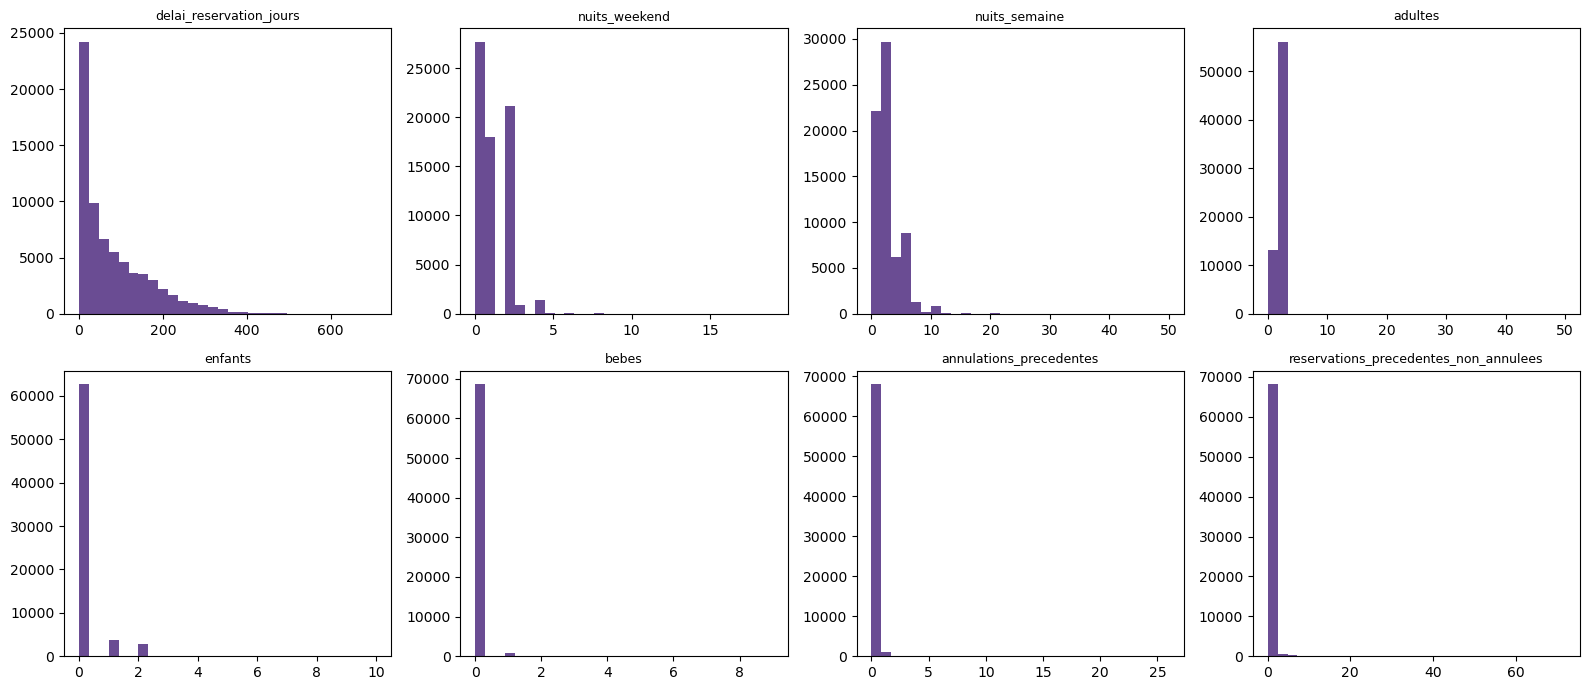

C:\Users\ludiv\Documents\Simplon\Brief groupe\Hotel_Booking Ilyes Laurie\projet_hotel_booking\notebook\graphiques\histogrammes_numeriques.png


In [32]:
# Trace un histogramme pour chacune des 8 colonnes numériques du train et l'enregistre sur le PC
colonnes_numeriques = ['delai_reservation_jours', 'nuits_weekend', 'nuits_semaine', 'adultes', 'enfants', 'bebes', 'annulations_precedentes', 'reservations_precedentes_non_annulees']

os.makedirs('../assets/graphiques', exist_ok=True)                 

fig, axes = plt.subplots(2, 4, figsize=(16, 7))              # une grille de 2 lignes et 4 colonnes de graphiques
for ax, col in zip(axes.ravel(), colonnes_numeriques):       
    ax.hist(X_train_enco[col], bins=30, color='#6A4C93')    # histogramme : combien de réservations par valeur
    ax.set_title(col, fontsize=9)                            
plt.tight_layout()                                           # évite que les titres se chevauchent
plt.savefig('graphiques/histogrammes_numeriques.png', dpi=150, bbox_inches='tight')   # enregistre l'image
plt.show()                                                   
print(os.path.abspath('graphiques/histogrammes_numeriques.png')) 

In [33]:
X_train_enco[colonnes_numeriques].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
delai_reservation_jours,69309.0,80.03,85.91,0.0,12.0,49.0,125.0,709.0
nuits_weekend,69309.0,1.01,1.03,0.0,0.0,1.0,2.0,19.0
nuits_semaine,69309.0,2.64,2.03,0.0,1.0,2.0,4.0,50.0
adultes,69309.0,1.88,0.59,0.0,2.0,2.0,2.0,50.0
enfants,69309.0,0.14,0.46,0.0,0.0,0.0,0.0,10.0
bebes,69309.0,0.01,0.11,0.0,0.0,0.0,0.0,9.0
annulations_precedentes,69309.0,0.03,0.38,0.0,0.0,0.0,0.0,26.0
reservations_precedentes_non_annulees,69309.0,0.19,1.76,0.0,0.0,0.0,0.0,72.0


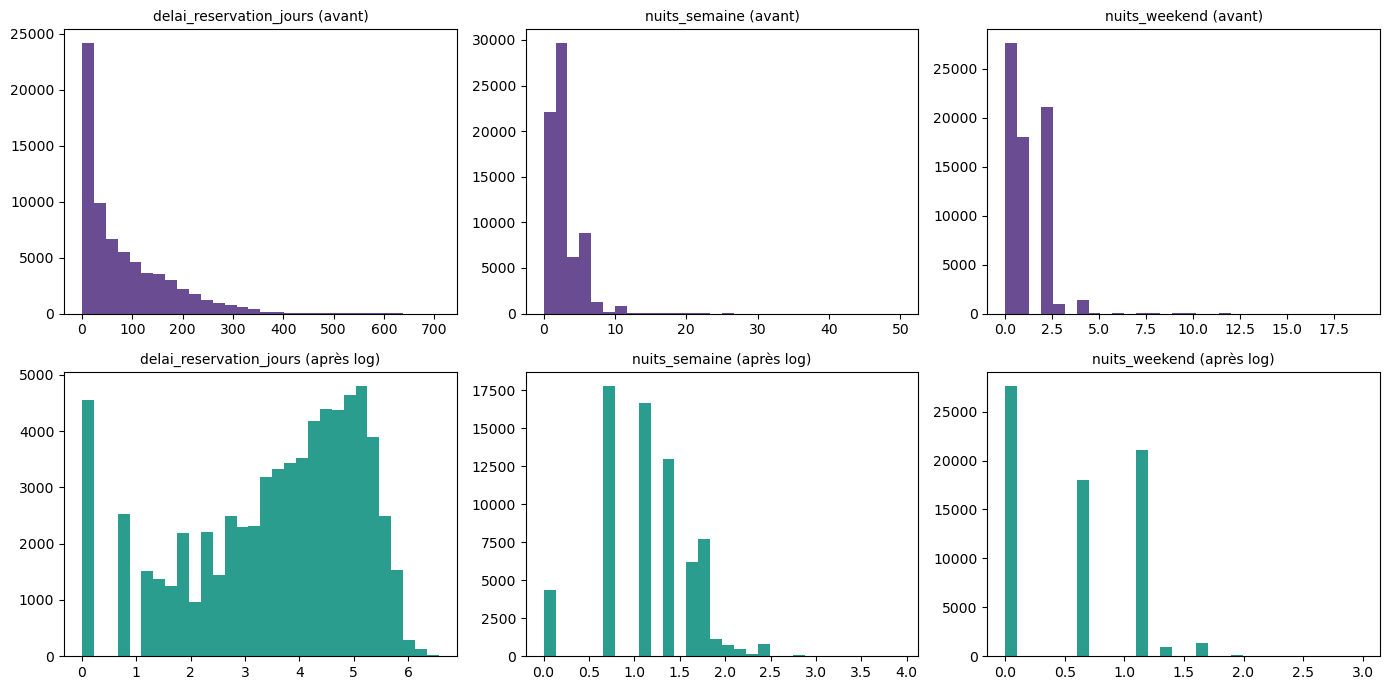

In [35]:
# Compare la forme de 3 colonnes avant et après log (log1p) et enregistre l'image
cols_log = ['delai_reservation_jours', 'nuits_semaine', 'nuits_weekend']

fig, axes = plt.subplots(2, 3, figsize=(14, 7))                              # 2 lignes (avant, après) et 3 colonnes
for i, col in enumerate(cols_log):
    axes[0, i].hist(X_train_enco[col], bins=30, color='#6A4C93')            # ligne du haut : valeurs d'origine
    axes[0, i].set_title(col + ' (avant)', fontsize=10)
    axes[1, i].hist(np.log1p(X_train_enco[col]), bins=30, color='#2A9D8F')  # ligne du bas : après log1p
    axes[1, i].set_title(col + ' (après log)', fontsize=10)
plt.tight_layout()
plt.savefig('graphiques/avant_apres_log.png', dpi=150, bbox_inches='tight')
plt.show()

**Choix de la mise à l'échelle**

Les 8 colonnes numériques n'ont ni la même forme ni la même échelle.

Pour la forme, `delai_reservation_jours` est très étalé vers les grandes valeurs. Beaucoup de réservations sont faites peu de temps avant l'arrivée et quelques-unes très longtemps avant. `nuits_semaine` est étalée de la même façon. `adultes` est concentrée sur 1 et 2. `enfants`, `bebes`, `annulations_precedentes` et `reservations_precedentes_non_annulees` sont presque toujours à 0.

Pour l'échelle, le délai va de 0 à 709 avec un écart type de 85,9. `bebes` va de 0 à 9 avec un écart type de 0,11. Plusieurs colonnes ont un maximum très éloigné de la médiane. `adultes` et `nuits_semaine` ont une médiane de 2 et un maximum de 50.

Le graphique avant et après log montre que le log rapproche les grandes valeurs du reste. Le délai, qui allait jusqu'à 700, va maintenant jusqu'à environ 6,5. `nuits_semaine`, qui allait jusqu'à 50, va jusqu'à environ 4. Pour `nuits_weekend`, la forme ne change presque pas.

**Décision.** On applique le log (`log1p`) à `delai_reservation_jours` et `nuits_semaine`, puis on standardise les 8 colonnes numériques. Les colonnes standardisées sont choisies par la variable `colonnes_a_standardiser`, qui contient par défaut les 8 colonnes numériques. On pourra tester une version avec seulement les 4 colonnes qui ne sont pas presque toujours à 0.

On ne passe pas `nuits_weekend` au log car sa forme ne change presque pas. On ne le fait pas non plus pour `adultes`, `enfants`, `bebes`, `annulations_precedentes` et `reservations_precedentes_non_annulees`, qui sont concentrées sur quelques valeurs ou presque toujours à 0. Elles sont seulement standardisées. 

In [36]:
# Applique le log (log1p) à delai_reservation_jours et nuits_semaine dans de nouvelles tables X_train_log et X_test_log
colonnes_log = ['delai_reservation_jours', 'nuits_semaine']

X_train_log = X_train_enco.copy()                                      
X_test_log = X_test_enco.copy()                                       

X_train_log[colonnes_log] = np.log1p(X_train_enco[colonnes_log])       # applique le log au train
X_test_log[colonnes_log] = np.log1p(X_test_enco[colonnes_log])         # applique le même log au test

print(X_train_log[colonnes_log].max())

delai_reservation_jours    6.565265
nuits_semaine              3.931826
dtype: float64


In [37]:
# Définit les deux listes de colonnes à standardiser et la variable qui choisit laquelle on utilise
colonnes_numeriques = ['delai_reservation_jours', 'nuits_weekend', 'nuits_semaine', 'adultes', 'enfants', 'bebes', 'annulations_precedentes', 'reservations_precedentes_non_annulees']   # les 8 colonnes
colonnes_variees = ['delai_reservation_jours', 'nuits_weekend', 'nuits_semaine', 'adultes']                                                                                           # les 4 colonnes qui n'sont pas presque toujours à 0

colonnes_a_standardiser = colonnes_numeriques    # par défaut les 8 (à remplacer par colonnes_variees pour tester l'autre version)
print(colonnes_a_standardiser)

['delai_reservation_jours', 'nuits_weekend', 'nuits_semaine', 'adultes', 'enfants', 'bebes', 'annulations_precedentes', 'reservations_precedentes_non_annulees']


In [38]:
# Standardise les colonnes de colonnes_a_standardiser (moyenne et écart type appris sur le train) dans de nouvelles tables X_train_final et X_test_final
X_train_final = X_train_log.copy()      
X_test_final = X_test_log.copy()        

scaler = StandardScaler()               # l'outil de standardisation
X_train_final[colonnes_a_standardiser] = scaler.fit_transform(X_train_log[colonnes_a_standardiser])   
X_test_final[colonnes_a_standardiser] = scaler.transform(X_test_log[colonnes_a_standardiser])       

print(X_train_final[colonnes_a_standardiser].mean().round(2))
print(X_train_final[colonnes_a_standardiser].std().round(2))

delai_reservation_jours                  0.0
nuits_weekend                            0.0
nuits_semaine                            0.0
adultes                                  0.0
enfants                                  0.0
bebes                                   -0.0
annulations_precedentes                 -0.0
reservations_precedentes_non_annulees   -0.0
dtype: float64
delai_reservation_jours                  1.0
nuits_weekend                            1.0
nuits_semaine                            1.0
adultes                                  1.0
enfants                                  1.0
bebes                                    1.0
annulations_precedentes                  1.0
reservations_precedentes_non_annulees    1.0
dtype: float64


In [39]:
# Affiche le maximum de chaque colonne numérique après standardisation (en écarts types)
X_train_final[colonnes_numeriques].max().round(1)

delai_reservation_jours                   1.9
nuits_weekend                            17.5
nuits_semaine                             5.3
adultes                                  80.9
enfants                                  21.5
bebes                                    81.2
annulations_precedentes                  67.9
reservations_precedentes_non_annulees    40.7
dtype: float64

La standardisation part de `X_train_log` et `X_test_log` et crée deux nouvelles tables, `X_train_final` et `X_test_final`. Les colonnes standardisées sont celles de la variable `colonnes_a_standardiser`. Par défaut elle contient les 8 colonnes numériques. On pourra la changer plus tard pour tester une autre liste.

Sur le train, la moyenne de ces colonnes vaut 0 et leur écart type vaut 1. Le `-0.0` de certaines colonnes est un arrondi de très petits nombres. Le test a été mis à l'échelle avec la moyenne et l'écart type du train.

### 4.4 Vérification

On vérifie que `X_train_final` et `X_test_final` ont les mêmes colonnes et aucune valeur manquante. On vérifie aussi que les cibles ont la bonne taille.

In [40]:
print(X_train_final.shape, y_train.shape)
print(X_test_final.shape, y_test.shape)
print(list(X_train_final.columns) == list(X_test_final.columns))
print(X_train_final.isna().sum().sum(), X_test_final.isna().sum().sum())

(69309, 114) (69309,)
(17328, 114) (17328,)
True
0 0


`X_train_final` a 69 309 lignes et 114 colonnes. `X_test_final` a 17 328 lignes et 114 colonnes. Les cibles `y_train` et `y_test` ont le même nombre de lignes. Le train et le test ont exactement les mêmes colonnes dans le même ordre. Il ne reste aucune valeur manquante.

La préparation des données est terminée.

<a id="modeles"></a>
## 5. Modèles

On entraîne trois modèles de classification avec leurs paramètres par défaut : une régression logistique, un arbre de décision et une Random Forest. On les entraîne sur `X_train_final` et `y_train`. Leurs résultats sont regardés en section 6 et leurs paramètres sont testés en section 7.

### 5.1 Modèle de référence

Le modèle de référence est un `DummyClassifier`. Il ignore les colonnes et tire au sort la réponse selon la part d'annulations du train (stratégie `stratified`). Il sert de point de comparaison. Un vrai modèle doit faire mieux que lui. 

In [51]:
modele_dummy = DummyClassifier(strategy='stratified', random_state=42)   
modele_dummy.fit(X_train_final, y_train)                                
print(modele_dummy.class_prior_)           

[0.72315284 0.27684716]


Le modèle de référence a retenu les proportions du train : 72,3 % de réservations non annulées et 27,7 % d'annulées.

### 5.2 Régression logistique

La régression logistique calcule pour chaque colonne un coefficient. Elle en déduit la probabilité qu'une réservation soit annulée. C'est un modèle linéaire, il a besoin de colonnes à des échelles comparables.

In [43]:
# Entraîne une régression logistique avec ses paramètres par défaut sur le train
modele_logreg = LogisticRegression(random_state=42)      # crée le modèle (random_state fixe le hasard pour retrouver le même résultat)
modele_logreg.fit(X_train_final, y_train)                # l'entraîne : il apprend les coefficients sur le train
print(modele_logreg.n_iter_)                             # nombre d'itérations utilisées pour converger

[69]


La régression logistique est entraînée avec ses paramètres par défaut. Elle converge en 69 itérations, sous la limite de 100. Les résultats sont regardés en section 6.

### 5.3 Arbre de décision

L'arbre de décision pose une suite de questions sur les colonnes. Il sépare ainsi les réservations en groupes de plus en plus homogènes. Il ne dépend pas de l'échelle des colonnes.

In [45]:
# Entraîne un arbre de décision avec ses paramètres par défaut sur le train
modele_arbre = DecisionTreeClassifier(random_state=42)   # crée le modèle (random_state fixe le hasard pour retrouver le même arbre)
modele_arbre.fit(X_train_final, y_train)                 # l'entraîne sur le train
print(modele_arbre.get_depth(), modele_arbre.get_n_leaves())   # profondeur de l'arbre et nombre de feuilles

55 14765


L'arbre est entraîné avec ses paramètres par défaut. Il a une profondeur de 55 et 14 765 feuilles pour 69 309 réservations d'entraînement. C'est un arbre très ramifié. Sans limite, il continue de poser des questions jusqu'à séparer presque chaque réservation. Il risque donc de trop coller au train. On testera sa profondeur maximale en 7.2.

### 5.4 Random Forest

La Random Forest entraîne plusieurs arbres de décision, chacun sur une partie différente des données et des colonnes. Elle regroupe leurs réponses par vote. Elle ne dépend pas de l'échelle des colonnes.

In [47]:
# Entraîne une Random Forest avec ses paramètres par défaut sur le train
modele_rf = RandomForestClassifier(random_state=42, n_jobs=-1)   # crée le modèle (n_jobs=-1 utilise tous les coeurs de l'ordinateur pour aller plus vite)
modele_rf.fit(X_train_final, y_train)                            # l'entraîne sur le train
print(len(modele_rf.estimators_))                                # nombre d'arbres dans la forêt

100


La Random Forest est entraînée avec ses paramètres par défaut. Elle contient 100 arbres.

<a id="resultats"></a>
## 6. Premiers résultats

On évalue les modèles de départ par validation croisée sur le train. Le train est coupé en 5 parties. Pour chaque partie, un modèle neuf est entraîné sur les 4 autres et prédit celle qu'il n'a pas vue. Chaque réservation du train a ainsi une prédiction faite par un modèle qui ne l'a pas vue. Le test n'est pas utilisé ici. Il est gardé pour l'évaluation finale.

In [52]:
# Prédit la probabilité d'annulation de chaque réservation du train par validation croisée, pour les quatre modèles
nb_plis = 5                                                                            # nombre de parties du train
plis = StratifiedKFold(n_splits=nb_plis, shuffle=True, random_state=42)                # découpe le train en 5 parties qui gardent la même part d'annulations

proba_dummy = cross_val_predict(modele_dummy, X_train_final, y_train, cv=plis, method='predict_proba')[:, 1]     # modèle de référence
proba_logreg = cross_val_predict(modele_logreg, X_train_final, y_train, cv=plis, method='predict_proba')[:, 1]   # régression logistique
proba_arbre = cross_val_predict(modele_arbre, X_train_final, y_train, cv=plis, method='predict_proba')[:, 1]     # arbre de décision
proba_rf = cross_val_predict(modele_rf, X_train_final, y_train, cv=plis, method='predict_proba')[:, 1]           # Random Forest

pred_dummy = (proba_dummy > 0.5).astype(int)         # annulée (1) si la probabilité dépasse 0,5, sinon pas annulée (0)
pred_logreg = (proba_logreg > 0.5).astype(int)
pred_arbre = (proba_arbre > 0.5).astype(int)
pred_rf = (proba_rf > 0.5).astype(int)
print(pred_dummy.shape, pred_logreg.shape, pred_arbre.shape, pred_rf.shape)

(69309,) (69309,) (69309,) (69309,)


### 6.1 Matrices de confusion

### 6.2 Tableau des métriques

<a id="ajustement"></a>
## 7. Ajustement des paramètres

### 7.1 Régression logistique

### 7.2 Arbre de décision

### 7.3 Random forest

### 7.4 Validation croisée

<a id="importance"></a>
## 8. Importance des variables

### 8.1 Régression logistique

### 8.2 Arbre de décision

### 8.3 Random Forest

### 8.4 Comparaison

<a id="choix"></a>
## 9. Choix du modèle

### 9.1 Évaluation sur le test

### 9.2 Tableau comparatif

### 9.3 Modèle retenu

<a id="erreurs"></a>
## 10. Analyse des erreurs

### 10.1 Faux négatifs et faux positifs

### 10.2 Réservations les plus ratées

### 10.3 Conséquences pour l'hôtel

<a id="conclusion"></a>
## 11. Conclusion

In [ ]:
df.info()

In [ ]:
df['nuits_weekend'].unique()

In [ ]:
# Pour les séjours avec plus de 2 nuits de week-end, regarde le minimum de nuits de semaine
df_ml[df_ml['nuits_weekend'] > 2].groupby('nuits_weekend')['nuits_semaine'].agg(['min', 'median', 'count'])

In [ ]:
df['adultes'].unique()